## Zadanie domowe: BBHE i DSIHE

W klasycznym wyrównywaniu histogramu HE  po wykonaniu operacji jasność obrazu ulega zmianie.
Dało się to zaobserwować podczas przeprowadzonych eksperymentów.
Jeśli nie to należy uruchomić skrypt z sekcji A i zwrócić na to uwagę.
Średnia jasność dąży do środkowego poziomu szarości.
Jest to wada i dlatego klasyczne HE ma ograniczone zastosowanie.

Powstało sporo metod, które eliminują to niekorzystne zjawisko.
Najprostsze z nich polegają na dekompozycji obrazu wejściowego na dwa podobrazy (wg. pewnego kryterium).
Następnie operacja HE wykonywana jest dla tych podobrazów.

Dwie znane z literatury metody to:
- Bi-Histogram Equalization
- DSIHE - Dualistic Sub-Image Histogram Equalization

W metodzie BBHE za kryterium podziału przyjmuje się średnią jasność w obrazie.
W DSIHE obraz dzieli się na dwa podobrazy o takiej samej liczbie pikseli (jaśniejszych i ciemniejszych).

W ramach zadania należy zaimplementować wybraną metodę: BBHE lub DSIHE (ew. obie).

1. Wczytaj obraz *jet.bmp* i wylicz jego histogram.
2. W kolejnym kroku należy wyznaczyć próg podziału obrazu na dwa podobrazy (*lm*).
3. Dla BBHE wyznacz średnią jasność obrazu. Dla DSIHE można wykorzystać histogram skumulowany.
Należy znaleźć poziom jasności który znajduje się "w połowie" histogramu skumulowanego.
W tym celu warto stworzyć tablicę, zawierającą moduł histogramu skumulowanego pomniejszonego o połowę liczby pikseli.
Następnie znaleźć minimum - `np.argmin`.
4. Dalej należy podzielić histogram oryginalnego obrazu na dwa histogramy *H1* i *H2*.
Dla każdego z nich wyliczyć histogram skumulowany ($C_1$ i $C_2$) i wykonać normalizację.
Normalizacja polega na podzieleniu każdego histogramu przez jego największy element.
5. Na podstawie histogramów skumulowanych należy stworzyć przekształcenie LUT.
Należy tak przeskalować $C_1$ i $C_2$, aby uzyskać jednorodne przekształcenie.
Tablicę $C_1$ wystarczy pomnożyć przez próg podziału.
Tablicę $C_2$ należy przeskalować do przedziału: $<lm+1; 255>$, gdzie $lm$ jest progiem podziału.<br>
$C_{1n} = (lm)*C1;$<br>
$C_{2n} = lm+1 + (255-lm-1)*C2;$<br>
Następnie dwie części tablicy przekodowań należy połączyć.
6. Na koniec należy wykonać operację LUT i wyświetlić wynik wyrównywania histogramu.
Porównaj wynik operacji BBHE lub DSIHE z klasycznym HE.

In [1]:
import cv2
import os
import requests
from matplotlib import pyplot as plt
import numpy as np

fileName = 'jet.bmp'
url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/03_Histogram/' # wasnt defined
if not os.path.exists(fileName) :
    r = requests.get(url + fileName, allow_redirects=True, timeout=10)
    with open(fileName, 'wb') as file:
        file.write(r.content)

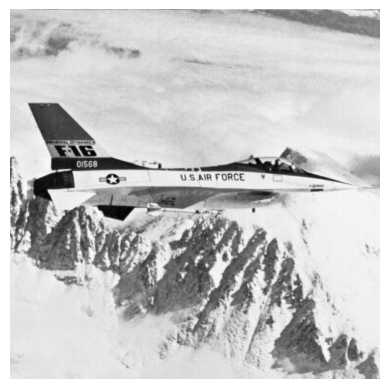

In [2]:
# zaimplementujmy BBHE

image = cv2.imread('jet.bmp', cv2.IMREAD_GRAYSCALE)
hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()

plt.imshow(image,cmap='gray')
plt.axis('off')
plt.show()

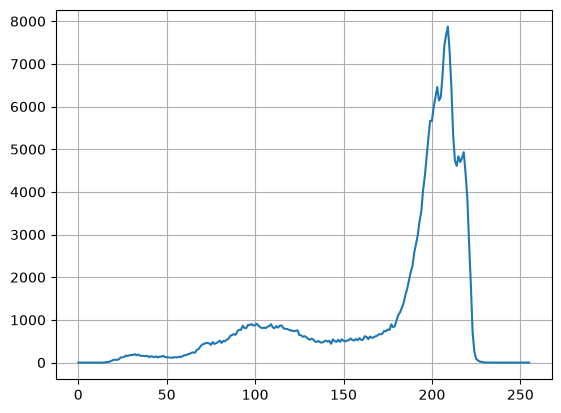

In [3]:
plt.plot(hist)
plt.grid()
plt.show()

In [4]:
lm = int(image.mean())
print('Próg podziału lm:', lm)

# dwie części histogramu: jasności 0–lm oraz lm+1–255
H1 = hist[:lm + 1]
H2 = hist[lm + 1:]

C1 = H1.cumsum()
C2 = H2.cumsum()
C1 = C1 / C1.max()
C2 = C2 / C2.max()

# each część skalujemy do jej własnego zakresu jasności
lut1 = lm * C1
lut2 = lm + 1 + (255 - lm - 1) * C2
lut = np.concatenate([lut1, lut2]).round().astype(np.uint8)

bbhe = cv2.LUT(image, lut)
he = cv2.equalizeHist(image)

Próg podziału lm: 178


Oryginał: średnia jasność = 178.02
HE: średnia jasność = 129.37
BBHE: średnia jasność = 179.76


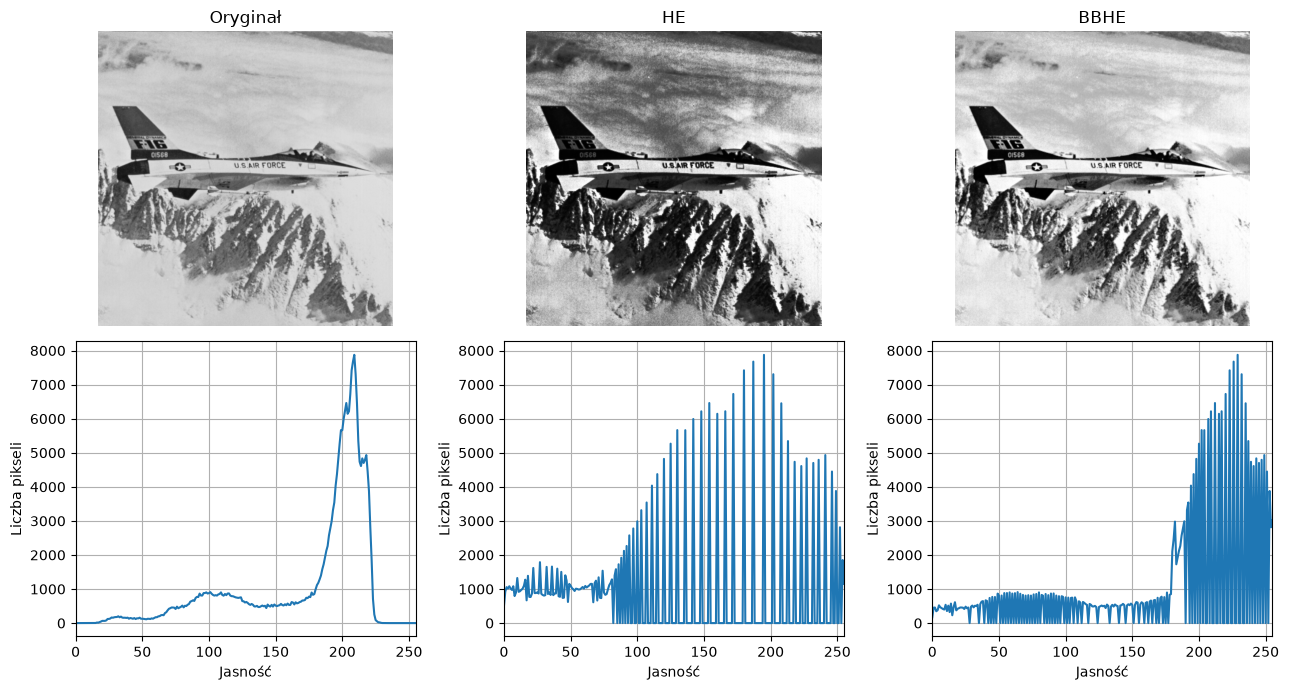

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
images = [image, he, bbhe]
titles = ['Oryginał', 'HE', 'BBHE']

for i, (result, title) in enumerate(zip(images, titles)):
    axs[0, i].imshow(result, cmap='gray', vmin=0, vmax=255)
    axs[0, i].set_title(title)
    axs[0, i].axis('off')

    result_hist = cv2.calcHist([result], [0], None, [256], [0, 256])
    axs[1, i].plot(result_hist)
    axs[1, i].set_xlim(0, 255)
    axs[1, i].set_xlabel('Jasność')
    axs[1, i].set_ylabel('Liczba pikseli')
    axs[1, i].grid()
    print(f'{title}: średnia jasność = {result.mean():.2f}')

plt.tight_layout()
plt.show()

In [6]:
# BBHE lepiej zachowuje średnią jasność obrazu `jet.bmp` niż klasyczne HE.
# Wyrównuje dwie części histogramu osobno, więc ciemniejsze i jaśniejsze piksele pozostają po swoich stronach progu. Nie gwarantuje jednak zachowania średniej dokładnie.